# SlowPaper - CLIP

박서준 (인공지능학과)

- 논문: *Learning Transferable Visual Models From Natural Language Supervision* (Radford et al., 2021, OpenAI)
- 링크: https://arxiv.org/abs/2103.00020
- 코드: https://github.com/openai/CLIP

SlowPaper 질문 5개에 답을 정리하고, 논문 내용 중 zero-shot 분류랑 프롬프트 부분을 직접 돌려봤다. Abstract랑 Figure 1을 먼저 보고 방법(2장), zero-shot 결과(3장), 한계(6장) 위주로 읽었다. 정리하면서 AI 도구 도움을 받았고 숫자는 논문 원문에서 다시 확인했다.

6장 작은 실험은 이미지가 4장뿐이라 결론 내기가 어려워서, 7장에서 VisA pcb4(정상 1,005장, 불량 100장)로 다시 해봤다.

## 1. 왜 이 논문을 선택했는가?

SlowPaper 논문으로 CLIP이 정해져 있었는데, 이번 과정에서 계속 나온 모델이라 제대로 읽어보고 싶었다. 8번 실습 AnomalyAny 코드에도 `clip_loss.py`가 있어서 생성한 이미지가 "crack" 같은 설명이랑 맞는지를 CLIP으로 점수 매기고 있었다. VLM 실습에서 다룬 이미지랑 글을 같이 이해하는 모델도 여기서 시작한 거라 출발점을 알고 싶었다.

## 2. 어떤 연구 분야인가?

이미지랑 텍스트를 같이 다루는 멀티모달 표현 학습이다. 사람이 단 라벨 대신 인터넷 이미지 설명 글을 학습 신호로 쓰는 자연어 지도 학습(natural language supervision), 그리고 따로 학습 안 한 데이터셋에 바로 쓰는 zero-shot transfer가 핵심이다.

## 3. 어떤 문제가 있었는가?

- 기존 분류 모델은 ImageNet 1,000개처럼 정해진 클래스만 맞히게 학습된다. 새로운 걸 인식하려면 라벨 데이터를 또 모아서 다시 학습해야 한다.
- 사람이 라벨 다는 데이터는 비싸서 크게 늘리기 어렵다. 반면 NLP는 인터넷 텍스트로 사전학습한 GPT-3가 추가 학습 없이도 여러 작업을 하고 있었다.
- 이미지 설명 글로 학습하려는 시도는 전에도 있었는데 성능이 낮았다. Visual N-Grams는 ImageNet zero-shot이 11.5%였다.
- ImageNet에서 잘하는 모델도 스케치처럼 스타일이 바뀌면 성능이 크게 떨어졌다.

## 4. 그 문제를 어떻게 해결하면 좋을까?

논문에서 한 방법은 이렇다.

1. 인터넷에서 (이미지, 텍스트) 쌍 4억 개(WIT)를 모았다.
2. 이미지 인코더(ResNet 또는 ViT)랑 텍스트 인코더(Transformer)를 같이 학습한다. 배치 안의 N개 이미지와 N개 문장으로 N×N 유사도를 만들고, 진짜 짝인 칸만 점수가 높아지게 학습한다(contrastive learning).
3. 캡션을 그대로 생성하게 하면 단어 묶음(bag-of-words)을 맞히는 방식보다 3배 느렸고, "어떤 글이 이 이미지의 짝인지"만 맞히는 대조 학습으로 바꾸니 거기서 4배 더 효율이 좋아졌다고 한다.
4. 학습이 끝나면 클래스 이름을 `"A photo of a {label}."` 같은 문장으로 바꿔 텍스트 임베딩을 만들고, 이미지 임베딩이랑 제일 가까운 문장을 고르면 추가 학습 없이 분류기가 된다.
5. 문장 틀을 데이터셋에 맞게 바꾸고 여러 문장(ImageNet은 80개)을 앙상블하면 더 오른다. ImageNet에서 기본 문장으로 1.3%, 앙상블로 3.5%가 더해져서 5% 가까이 올랐다.

제일 기억에 남는 건 클래스를 0, 1, 2 같은 번호가 아니라 문장으로 표현한다는 점이었다. 불량 종류가 계속 새로 생기는 공장에서도 라벨을 다시 모으지 않고 "a photo of a PCB with a burnt chip"처럼 설명만 바꿔서 검사할 수 있으면 좋겠다고 생각했다. 근데 작은 결함까지 구분하는지는 따로 봐야 할 것 같아서 6장, 7장에서 직접 해봤다.

## 5. 시도한 결과는 어떠한가?

- 제일 큰 모델(ViT-L/14@336px)은 ImageNet zero-shot 76.2%로, ImageNet 학습 데이터 128만 장을 하나도 안 쓰고 ResNet-50이랑 비슷한 성능을 냈다. top-5는 95%다.
- 27개 데이터셋 중 16개에서 zero-shot CLIP이 ResNet-50 특징에 지도 학습한 선형 분류기보다 좋았다.
- ImageNet-R, ObjectNet, ImageNet Sketch처럼 분포가 바뀐 데이터에서 ImageNet 정확도와의 차이를 최대 75%까지 줄였다. 기존 ImageNet 모델보다 훨씬 덜 흔들린다.
- 한계도 있었다. 위성 사진(EuroSAT), 림프절 종양(PatchCamelyon), 물체 개수 세기(CLEVRCounts), 교통 표지판(GTSRB) 같은 전문적이거나 추상적인 작업은 약했고, MNIST는 88%로 픽셀에 로지스틱 회귀를 한 것보다도 낮았다.
- 학습 비용이 엄청 크다. RN50x64는 V100 592장으로 18일, ViT-L/14는 V100 256장으로 12일 걸렸다.

## 6. 직접 해본 작은 실험

HF에 있는 CLIP(ViT-B/32)으로 두 가지를 해봤다(Colab CPU).

1. 프롬프트 효과: 이미지 4장(hazelnut, table, road, circuit board)을 4개 클래스로 zero-shot 분류할 때 클래스 이름만 넣은 경우랑 `A photo of a {label}.` 문장을 넣은 경우의 정답 확률 비교
2. 결함 구분: 정상 PCB 사진이랑 같은 사진에 검은 얼룩을 그려 넣은 사진을 "normal / damaged / burnt" 문장으로 구분하는지

이미지는 8번 실습 AnomalyAny 예제 이미지랑 강의 자료 PCB 정상 이미지(normal.png)를 썼다.

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

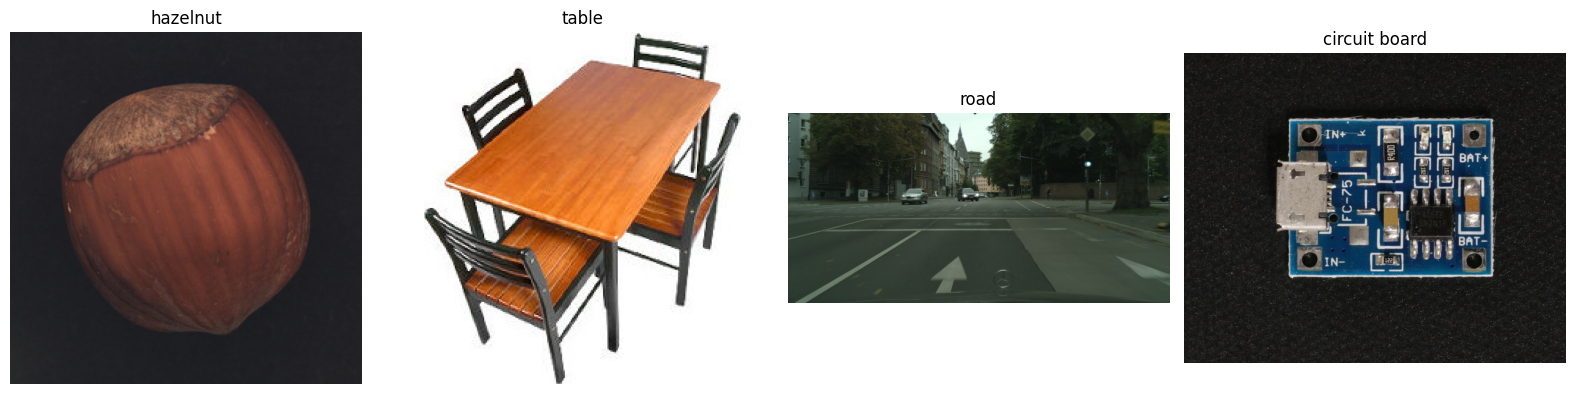

In [1]:
import torch
import requests
import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from PIL import Image, ImageDraw
from transformers import CLIPModel, CLIPProcessor

# CLIP 중에 제일 작은 ViT-B/32 (논문 표의 ViT-L/14@336px보다 작음)
model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').eval()
processor = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')

base = 'https://raw.githubusercontent.com/EPFL-IMOS/AnomalyAny/main/'
urls = {
    'hazelnut': base + 'example_image/000.png',
    'table': base + 'example_web/table.jpg',
    'road': base + 'example_image/road.png',
    'circuit board': 'https://drive.usercontent.google.com/download?id=1sxnp0fmdDJOfuRyQ07e0zQeetA4RytrS&export=download',  # 강의 자료 normal.png
}
images = {name: Image.open(BytesIO(requests.get(url, timeout=60).content)).convert('RGB') for name, url in urls.items()}
labels = list(images.keys())

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

실험에 쓴 이미지 4장이다. 서로 완전히 다른 물체라 분류 자체는 쉬운 편이다.

In [2]:
def zero_shot(image, texts):
    """이미지 1장 vs 문장 여러 개 유사도 -> softmax 확률 (논문 Figure 1의 3번)"""
    inputs = processor(text=texts, images=image, return_tensors='pt', padding=True)
    with torch.no_grad():
        logits = model(**inputs).logits_per_image  # 코사인 유사도 x 학습된 temperature
    return logits.softmax(dim=-1)[0]

# 실험 1: 클래스 이름만 쓴 경우 vs 논문 기본 문장 틀
templates = {'label only': '{}', 'A photo of a {}.': 'A photo of a {}.'}
rows = []
for prompt_name, template in templates.items():
    texts = [template.format(label) for label in labels]
    for true_label, img in images.items():
        probs = zero_shot(img, texts)
        rows.append({
            'prompt': prompt_name,
            'image': true_label,
            'prediction': labels[probs.argmax().item()],
            'p(correct)': round(probs[labels.index(true_label)].item(), 4),
        })
result = pd.DataFrame(rows)
print(result.pivot(index='image', columns='prompt', values='p(correct)'))
print()
print('예측이 맞은 개수:', result.assign(ok=result['prediction'] == result['image']).groupby('prompt')['ok'].sum().to_dict())

prompt         A photo of a {}.  label only
image                                      
circuit board            0.9986      0.9987
hazelnut                 0.9997      0.9985
road                     0.9952      0.9851
table                    1.0000      0.9997

예측이 맞은 개수: {'A photo of a {}.': 4, 'label only': 4}


실험 1 결과 (정답 클래스 확률)

| 이미지 | label only | A photo of a {}. |
|---|---:|---:|
| circuit board | 0.9987 | 0.9986 |
| hazelnut | 0.9985 | 0.9997 |
| road | 0.9851 | 0.9952 |
| table | 0.9997 | 1.0000 |

둘 다 4장을 다 맞혔고 확률도 0.98을 넘었다. 문장 틀을 쓰니 3장(hazelnut, road, table)에서 조금 올랐고 road가 0.9851 → 0.9952로 제일 많이 올랐다. 근데 클래스가 4개뿐이고 서로 너무 달라서 차이가 작다. 논문의 1.3%는 1,000개 클래스처럼 헷갈리는 게 많을 때 얘기라 이걸로 같은 효과를 봤다고 하긴 어렵다.

normal {'normal circuit board': 0.794, 'damaged circuit board': 0.16, 'burnt circuit board': 0.046}
dark spot drawn {'normal circuit board': 0.734, 'damaged circuit board': 0.195, 'burnt circuit board': 0.071}


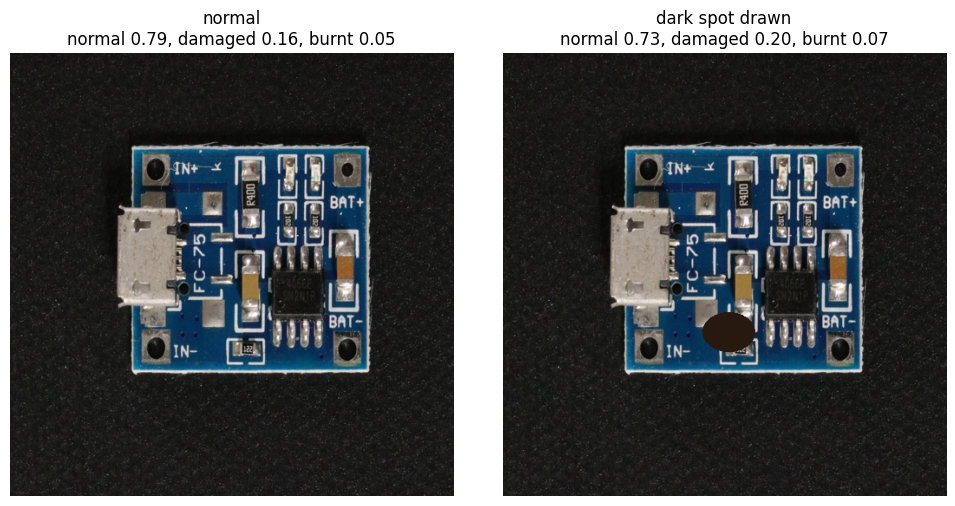

In [3]:
# 실험 2: 정상 PCB vs 검은 얼룩을 그려 넣은 PCB를 문장으로 구분할 수 있을까?
normal_pcb = images['circuit board'].resize((512, 512))
spot_pcb = normal_pcb.copy()
ImageDraw.Draw(spot_pcb).ellipse([230, 300, 290, 345], fill=(40, 25, 15))  # 보드 아래쪽에 탄 자국처럼 어두운 얼룩

defect_texts = [
    'a photo of a normal circuit board',
    'a photo of a damaged circuit board',
    'a photo of a burnt circuit board',
]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, img) in zip(axes, [('normal', normal_pcb), ('dark spot drawn', spot_pcb)]):
    probs = zero_shot(img, defect_texts)
    scores = {text.replace('a photo of a ', ''): round(p.item(), 3) for text, p in zip(defect_texts, probs)}
    print(name, scores)
    ax.imshow(img)
    ax.set_title(f"{name}\n" + ', '.join(f'{k.split()[0]} {v:.2f}' for k, v in scores.items()))
    ax.axis('off')
plt.tight_layout()
plt.show()

실험 2 결과

| 이미지 | normal | damaged | burnt |
|---|---:|---:|---:|
| 정상 PCB | 0.794 | 0.160 | 0.046 |
| 검은 얼룩 그린 PCB | 0.734 | 0.195 | 0.071 |

눈으로 봐도 확실한 얼룩을 그렸는데 CLIP은 여전히 normal을 골랐다. damaged, burnt가 조금 오르긴 했는데 판정은 그대로다. 논문 6장(한계)에서 말한 것처럼 제조 결함처럼 전문적이고 작은 차이는 zero-shot으로는 약한 것 같다. 6번 실습에서 PaDiM처럼 정상 데이터로 따로 학습하는 방법이 왜 필요한지 이해가 됐다. 다만 그린 얼룩은 실제 결함이랑 모양도 다르고 1장뿐이라 일반화하긴 어렵다.

## 7. 추가 실험: 논문에서 말한 걸 제조 결함 데이터로 다시 확인

6장은 이미지 4장, 직접 그린 결함 1장이라 숫자를 믿기 어려웠다. 그래서 6번 실습 pcb4(정상 1,005장, 실제 불량 100장)로 다시 해봤다. 확인하고 싶었던 건 세 가지다.

| | 논문에서 말한 것 | 여기서 확인한 것 |
|---|---|---|
| 7-1 | 프롬프트 앙상블하면 zero-shot이 오른다(3.1.4절, ImageNet +3.5%p), 모델이 클수록 좋다 | 문장 1개 vs 여러 문장, ViT-B/32 vs ViT-L/14 |
| 7-2 | zero-shot CLIP은 같은 특징으로 학습한 4-shot 선형 분류기랑 비슷하다(Figure 6), 전문적인 작업에선 약하다(3.1.5절) | 클래스당 k장(1 ~ 30장)으로 linear probe를 학습하면 몇 장부터 zero-shot보다 나은지 |
| 7-3 | 논문은 주로 정확도만 봄 | linear probe 규제 강도랑 학습 장수를 바꿔서 과소적합 / 과적합 확인 |

분할은 6번 추가 분석이랑 같은 규칙(seed 0 ~ 4)으로 정상을 학습 603 / 검증 201 / 테스트 201, 불량을 학습 후보 30 / 검증 20 / 테스트 50으로 나눴다. linear probe의 C는 검증셋으로만 고르고 비교는 전부 테스트 AUROC로 했다. 분할 5개 평균 ± 표준편차랑, 같은 테스트 이미지로 구한 차이의 95% 신뢰구간을 같이 적었다. Colab T4에서 돌렸다.

In [1]:
# 7장 실험: 설정 + 데이터
import os, time, tarfile
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.models as models
from PIL import Image
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from transformers import CLIPModel, CLIPProcessor, CLIPTokenizer
import matplotlib.pyplot as plt

QUICK = False
SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]
N_BOOT = 300 if QUICK else 2000
DATA, CAT = './VisA', 'pcb4'
device = torch.device('cuda')
plt.rcParams['figure.dpi'] = 80

if not os.path.exists(f'{DATA}/{CAT}/image_anno.csv'):
    if not os.path.exists('VisA_20220922.tar'):
        !wget -q https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar
    with tarfile.open('VisA_20220922.tar') as tar:
        members = [m for m in tar.getmembers() if m.name.lstrip('./').startswith(CAT + '/')]
        tar.extractall(DATA, members=members, filter='data')
df = pd.read_csv(f'{DATA}/{CAT}/image_anno.csv')
paths = [f'{DATA}/{p}' if p.startswith(CAT + '/') else f'{DATA}/{CAT}/{p}' for p in df['image']]
labels = (df['label'] != 'normal').astype(int).values
IMGS = [Image.open(p).convert('RGB').resize((256, 256), Image.BILINEAR) for p in paths]  # 6번처럼 256x256


def make_split(seed):
    """6번 추가 분석이랑 같은 방식으로 섞음 (정상 분할 같음). 불량: 학습 후보 30 / 검증 20 / 테스트 50"""
    rng = np.random.RandomState(seed)
    nor = rng.permutation(np.where(labels == 0)[0])
    ano = rng.permutation(np.where(labels == 1)[0])
    return dict(train_n=nor[402:], val_n=nor[201:402], test_n=nor[:201], train_a=ano[:30], val_a=ano[30:50], test_a=ano[50:])


def fast_auc(y, s):
    y = np.asarray(y); r = rankdata(s); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def _boot_idx(rng, y):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    return np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]


def boot_ci(y, s, B=N_BOOT, seed=0):
    rng = np.random.RandomState(seed)
    return np.percentile([fast_auc(y[i], s[i]) for i in (_boot_idx(rng, y) for _ in range(B))], [2.5, 97.5])


def paired_diff_ci(y, s1, s2, B=N_BOOT, seed=0):
    rng = np.random.RandomState(seed); d = []
    for _ in range(B):
        i = _boot_idx(rng, y); d.append(fast_auc(y[i], s1[i]) - fast_auc(y[i], s2[i]))
    return fast_auc(y, s1) - fast_auc(y, s2), np.percentile(d, [2.5, 97.5])


print(torch.cuda.get_device_name(0), '| 이미지', len(IMGS), '|', {k: len(v) for k, v in make_split(0).items()})

Tesla T4 | 이미지 1105 | {'train_n': 603, 'val_n': 201, 'test_n': 201, 'train_a': 30, 'val_a': 20, 'test_a': 50}



In [2]:
# 이미지 특징 뽑기 (CLIP B/32, L/14, 비교용 ImageNet ResNet-50)
@torch.no_grad()
def clip_image_feats(name, bs=64):
    model = CLIPModel.from_pretrained(name, torch_dtype=torch.float16).to(device).eval()
    proc = CLIPProcessor.from_pretrained(name)
    out = []
    for i in range(0, len(IMGS), bs):
        px = proc(images=IMGS[i:i + bs], return_tensors='pt')['pixel_values'].to(device, torch.float16)
        emb = model.visual_projection(model.vision_model(pixel_values=px).pooler_output)  # get_image_features랑 같은 계산
        out.append(F.normalize(emb.float(), dim=-1).cpu())
    return model, torch.cat(out).numpy()


@torch.no_grad()
def resnet50_feats(bs=64):
    m = models.resnet50(weights='IMAGENET1K_V1').to(device).eval(); m.fc = torch.nn.Identity()
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    out = []
    for i in range(0, len(IMGS), bs):
        x = torch.from_numpy(np.stack([np.asarray(im.resize((224, 224), Image.BILINEAR)) for im in IMGS[i:i + bs]])).permute(0, 3, 1, 2).to(device).float() / 255.
        out.append(F.normalize(m((x - mean) / std), dim=-1).cpu())
    return torch.cat(out).numpy()


t0 = time.time()
CLIP_NAMES = {'ViT-B/32': 'openai/clip-vit-base-patch32', 'ViT-L/14': 'openai/clip-vit-large-patch14'}
clip_models, FEATS = {}, {}
for short, name in CLIP_NAMES.items():
    clip_models[short], FEATS[f'CLIP {short}'] = clip_image_feats(name)
FEATS['ResNet-50 (ImageNet)'] = resnet50_feats()
print({k: v.shape for k, v in FEATS.items()}, f'{time.time() - t0:.0f}초')

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth



{'CLIP ViT-B/32': (1105, 512), 'CLIP ViT-L/14': (1105, 768), 'ResNet-50 (ImageNet)': (1105, 2048)} 58초



### 7-1. Zero-shot: 문장 1개 vs 앙상블, 작은 모델 vs 큰 모델

- 문장 1개: 논문 기본 틀 `a photo of a {}.`에 "normal printed circuit board", "damaged printed circuit board"
- 앙상블: 문장 틀 8개 x 상태 표현 5개(정상: flawless, perfect, normal, good, without defect / 불량: damaged, defective, broken, flawed, with a defect). 논문처럼 클래스마다 텍스트 임베딩을 평균 냈다. 상태 표현을 섞는 건 CLIP으로 이상탐지를 한 WinCLIP(Jeong et al., CVPR 2023)을 참고했다.
- 불량 점수는 두 클래스 중 불량 쪽 softmax 확률(논문처럼 logit에 temperature 100을 곱함)

In [3]:
# zero-shot 분류기
OBJ = 'printed circuit board'
SINGLE = {'normal': ['a photo of a normal printed circuit board.'], 'anomaly': ['a photo of a damaged printed circuit board.']}
TEMPLATES = ['a photo of a {}.', 'a close-up photo of a {}.', 'a cropped photo of the {}.', 'a good photo of a {}.',
             'a bright photo of a {}.', 'a dark photo of a {}.', 'a low resolution photo of a {}.', 'an industrial photo of a {}.']
STATES = {'normal': ['flawless {}', 'perfect {}', 'normal {}', 'good {}', '{} without defect'],
          'anomaly': ['damaged {}', 'defective {}', 'broken {}', 'flawed {}', '{} with a defect']}
ENSEMBLE = {c: [t.format(s.format(OBJ)) for t in TEMPLATES for s in STATES[c]] for c in STATES}


@torch.no_grad()
def text_classifier(short, prompts):
    model = clip_models[short]; tok = CLIPTokenizer.from_pretrained(CLIP_NAMES[short])
    W = []
    for c in ['normal', 'anomaly']:
        t = tok(prompts[c], padding=True, return_tensors='pt').to(device)
        emb = model.text_projection(model.text_model(**t).pooler_output)  # get_text_features랑 같은 계산
        e = F.normalize(emb.float(), dim=-1).mean(0)  # 문장 임베딩 평균 (논문 3.1.4절)
        W.append(F.normalize(e, dim=0))
    return torch.stack(W).cpu().numpy(), model.logit_scale.exp().item()


ZS = {}
for short in CLIP_NAMES:
    for pname, prompts in [('single prompt', SINGLE), ('ensemble (40)', ENSEMBLE)]:
        W, scale = text_classifier(short, prompts)
        logits = scale * FEATS[f'CLIP {short}'] @ W.T
        p = np.exp(logits - logits.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
        ZS[f'{short} / {pname}'] = p[:, 1]  # 불량일 확률
print('문장 예시:', ENSEMBLE['anomaly'][:3], '... 총', len(ENSEMBLE['normal']) + len(ENSEMBLE['anomaly']), '문장')

rows, zs_test = [], {}
for seed in SEEDS:
    sp = make_split(seed); te = np.r_[sp['test_n'], sp['test_a']]
    yt = np.r_[np.zeros(len(sp['test_n'])), np.ones(len(sp['test_a']))]
    zs_test[seed] = (yt, {k: v[te] for k, v in ZS.items()})
    for k, v in ZS.items():
        pred_anom = v[te] > 0.5
        rows.append(dict(seed=seed, config=k, AUROC=fast_auc(yt, v[te]), acc_normal=(~pred_anom[yt == 0]).mean(), acc_defect=pred_anom[yt == 1].mean()))
dfZ = pd.DataFrame(rows)
g = dfZ.groupby('config')[['AUROC', 'acc_normal', 'acc_defect']]
print('\n[테스트셋 zero-shot, 분할 5개 평균 ± 표준편차] acc_normal/acc_defect = 확률 0.5 기준으로 정상/불량을 맞힌 비율')
print((g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)).to_string())
print('\n[seed 0 AUROC와 95% 신뢰구간]')
yt, S = zs_test[SEEDS[0]]
for k in ZS:
    lo, hi = boot_ci(yt, S[k]); print(f'  {k}: {fast_auc(yt, S[k]):.3f} [{lo:.3f}, {hi:.3f}]')
print('\n[차이 (앞 - 뒤)와 95% 신뢰구간]')
for a, b in [('ViT-B/32 / ensemble (40)', 'ViT-B/32 / single prompt'), ('ViT-L/14 / ensemble (40)', 'ViT-L/14 / single prompt'),
             ('ViT-L/14 / ensemble (40)', 'ViT-B/32 / ensemble (40)')]:
    txt, up, down = [], 0, 0
    for seed in SEEDS:
        yt, S = zs_test[seed]; d, (lo, hi) = paired_diff_ci(yt, S[a], S[b]); up += int(lo > 0); down += int(hi < 0)
        txt.append(f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]')
    print(f'  {a}  -  {b}\n    ' + ' | '.join(txt) + f'\n    -> 좋아짐 {up} / 나빠짐 {down} / 판단 불가 {len(SEEDS) - up - down} (분할 수)')

문장 예시: ['a photo of a damaged printed circuit board.', 'a photo of a defective printed circuit board.', 'a photo of a broken printed circuit board.'] ... 총 80 문장

[테스트셋 zero-shot, 분할 5개 평균 ± 표준편차] acc_normal/acc_defect = 확률 0.5 기준으로 정상/불량을 맞힌 비율
                                  AUROC     acc_normal    acc_defect
config                                                              
ViT-B/32 / ensemble (40)  0.708 ± 0.031      1.0 ± 0.0     0.0 ± 0.0
ViT-B/32 / single prompt  0.704 ± 0.032      1.0 ± 0.0     0.0 ± 0.0
ViT-L/14 / ensemble (40)  0.602 ± 0.014  0.653 ± 0.022  0.52 ± 0.051
ViT-L/14 / single prompt  0.737 ± 0.019      1.0 ± 0.0     0.0 ± 0.0

[seed 0 AUROC와 95% 신뢰구간]
  ViT-B/32 / single prompt: 0.675 [0.595, 0.750]
  ViT-B/32 / ensemble (40): 0.677 [0.595, 0.753]
  ViT-L/14 / single prompt: 0.728 [0.643, 0.806]
  ViT-L/14 / ensemble (40): 0.588 [0.503, 0.670]

[차이 (앞 - 뒤)와 95% 신뢰구간]
  ViT-B/32 / ensemble (40)  -  ViT-B/32 / single prompt
    +0.003 [-0.028, +0.032] | +0.001 [

| 설정 | 테스트 AUROC (분할 5개) | 확률 0.5 기준 판정 |
|---|---:|---|
| ViT-B/32, 문장 1개 | 0.704 ± 0.032 | 전부 정상 |
| ViT-B/32, 앙상블 40문장 | 0.708 ± 0.031 | 전부 정상 |
| ViT-L/14, 문장 1개 | 0.737 ± 0.019 | 전부 정상 |
| ViT-L/14, 앙상블 40문장 | 0.602 ± 0.014 | 정상 65%, 불량 52% 맞힘 |

AUROC 0.7이면 정상 1장, 불량 1장을 뽑았을 때 불량 쪽에 더 높은 점수를 줄 확률이 70%라는 거다(0.5가 찍기). 결함을 조금은 구분하지만 검사에 쓰기엔 많이 부족하다. 확률 0.5 기준으로 보면 세 설정은 불량 50장을 하나도 못 잡았다.

앙상블 효과는 재현이 안 됐다. ViT-B/32는 차이가 -0.015 ~ +0.020이고 5개 분할 다 신뢰구간이 0을 걸쳐서 차이가 없다. ViT-L/14는 오히려 0.09 ~ 0.16 떨어졌고 5개 분할 다 신뢰구간이 0보다 아래였다. 큰 모델이 항상 좋은 것도 아니었다. 앙상블끼리 보면 ViT-L/14가 B/32보다 낮았다(2개 분할은 확실히 낮고 3개는 판단 불가).

분할 하나만 보면 신뢰구간이 넓다(seed 0 ViT-L/14 문장 1개: 0.728 [0.643, 0.806]). 테스트 불량이 50장뿐이라 분할 하나로 0.03 정도 차이를 말하긴 어렵다.

논문 3.1.5절에서 zero-shot CLIP이 위성 사진(EuroSAT), 종양 탐지(PatchCamelyon) 같은 전문 작업에 약하다고 했는데 PCB 결함도 그쪽인 것 같다. 앙상블이 ViT-L/14에서 왜 나빠졌는지는 못 밝혔다. "flawless", "broken" 같은 단어가 작은 부품 결함이랑 잘 안 맞아서일 수도 있는데 추측이다.

### 7-2. 라벨 몇 장이면 zero-shot보다 나은가 (few-shot linear probe)

논문 Figure 6처럼 같은 이미지 특징 위에 로지스틱 회귀를 학습했다. 학습 데이터는 클래스당 k장(정상 k + 불량 k, k = 1, 2, 4, 8, 16, 30)이다. C는 0.01 ~ 100 중에서 검증 AUROC가 제일 높은 걸 골랐다. 비교로 ImageNet ResNet-50 특징에도 똑같이 해봤다(논문 Figure 5의 비교 대상이랑 같은 종류).

[테스트 AUROC, 분할 5개 평균 / 표준편차]
              mean                                              std                                   
feat CLIP ViT-B/32 CLIP ViT-L/14 ResNet-50 (ImageNet) CLIP ViT-B/32 CLIP ViT-L/14 ResNet-50 (ImageNet)
k                                                                                                     
1            0.818         0.726                0.653         0.127         0.217                0.299
2            0.889         0.856                0.697         0.109         0.151                0.284
4            0.945         0.928                0.871         0.034         0.045                0.096
8            0.965         0.967                0.918         0.016         0.018                0.058
16           0.969         0.971                0.943         0.010         0.014                0.033
30           0.973         0.977                0.958         0.011         0.012                0.022

비교용 zero-shot 테스트 AUROC: {'ViT-B/32 / ensem

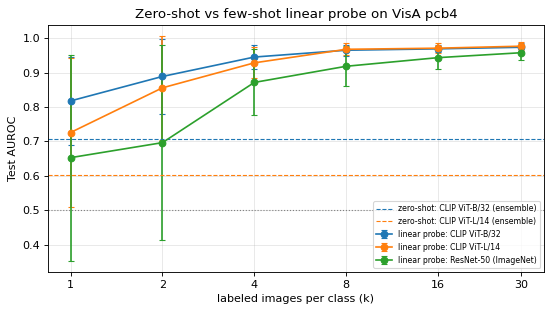

In [4]:
# few-shot linear probe
KS = [1, 2, 4, 8, 16, 30]
CS = [0.01, 0.1, 1, 10, 100]
rows, lp_hist = [], []
for seed in SEEDS:
    sp = make_split(seed)
    rng = np.random.RandomState(500 + seed)
    pn, pa = rng.permutation(sp['train_n']), rng.permutation(sp['train_a'])
    va = np.r_[sp['val_n'], sp['val_a']]; yv = np.r_[np.zeros(len(sp['val_n'])), np.ones(len(sp['val_a']))]
    te = np.r_[sp['test_n'], sp['test_a']]; yt = np.r_[np.zeros(len(sp['test_n'])), np.ones(len(sp['test_a']))]
    for fname, Fx in FEATS.items():
        for k in KS:
            tr = np.r_[pn[:k], pa[:k]]; ytr = np.r_[np.zeros(k), np.ones(k)]
            best = None
            for C in CS:
                clf = LogisticRegression(C=C, max_iter=5000).fit(Fx[tr], ytr)
                v = fast_auc(yv, clf.decision_function(Fx[va]))
                lp_hist.append(dict(seed=seed, feat=fname, k=k, C=C, train_acc=clf.score(Fx[tr], ytr),
                                    train_AUROC=fast_auc(ytr, clf.decision_function(Fx[tr])), val_AUROC=v))
                if best is None or v > best[0]:
                    best = (v, C, clf)
            rows.append(dict(seed=seed, feat=fname, k=k, C=best[1], val_AUROC=best[0], test_AUROC=fast_auc(yt, best[2].decision_function(Fx[te]))))
dfL = pd.DataFrame(rows); dfH = pd.DataFrame(lp_hist)
tab = dfL.groupby(['feat', 'k']).test_AUROC.agg(['mean', 'std']).round(3)
print('[테스트 AUROC, 분할 5개 평균 / 표준편차]')
print(tab.unstack(0).to_string())
zs_mean = dfZ.groupby('config').AUROC.mean()
print('\n비교용 zero-shot 테스트 AUROC:', zs_mean.round(3).to_dict())
for short in CLIP_NAMES:
    zs = zs_mean[f'{short} / ensemble (40)']
    m = dfL[dfL.feat == f'CLIP {short}'].groupby('k').test_AUROC.mean()
    above = [k for k in KS if m[k] > zs]
    print(f'CLIP {short}: zero-shot(앙상블) {zs:.3f}보다 평균이 높아지는 첫 k = {above[0] if above else "없음(30장까지)"}')

fig, ax = plt.subplots(figsize=(7, 4))
for j, fname in enumerate(FEATS):
    m = dfL[dfL.feat == fname].groupby('k').test_AUROC
    ax.errorbar(KS, m.mean().values, yerr=m.std().values, marker='o', capsize=3, label=f'linear probe: {fname}', color=f'C{j}')
for j, short in enumerate(CLIP_NAMES):
    ax.axhline(zs_mean[f'{short} / ensemble (40)'], color=f'C{j}', ls='--', lw=1, label=f'zero-shot: CLIP {short} (ensemble)')
ax.axhline(0.5, color='gray', ls=':', lw=1)
ax.set_xscale('log', base=2); ax.set_xticks(KS); ax.set_xticklabels(KS)
ax.set_xlabel('labeled images per class (k)'); ax.set_ylabel('Test AUROC'); ax.set_title('Zero-shot vs few-shot linear probe on VisA pcb4')
ax.legend(fontsize=7); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

테스트 AUROC, 분할 5개 평균 ± 표준편차

| k | CLIP ViT-B/32 | CLIP ViT-L/14 | ResNet-50 (ImageNet) |
|---:|---:|---:|---:|
| 1 | 0.818 ± 0.127 | 0.726 ± 0.217 | 0.653 ± 0.299 |
| 2 | 0.889 ± 0.109 | 0.856 ± 0.151 | 0.697 ± 0.284 |
| 4 | 0.945 ± 0.034 | 0.928 ± 0.045 | 0.871 ± 0.096 |
| 8 | 0.965 ± 0.016 | 0.967 ± 0.018 | 0.918 ± 0.058 |
| 16 | 0.969 ± 0.010 | 0.971 ± 0.014 | 0.943 ± 0.033 |
| 30 | 0.973 ± 0.011 | 0.977 ± 0.012 | 0.958 ± 0.022 |
| zero-shot 앙상블 | 0.708 | 0.602 | - |

그래프를 보면 세 선 모두 k=1 ~ 2에서 오차 막대가 엄청 길고, k=4부터 짧아지면서 0.87 ~ 0.95까지 올라간다. 점선(zero-shot)은 같은 색 k=1 점보다도 아래에 있다.

논문에선 zero-shot이 4-shot이랑 비슷했는데 여기선 클래스당 1장만 써도 평균은 zero-shot보다 높았다. ViT-L/14 문장 1개 zero-shot(0.737)이 1-shot(0.726)이랑 비슷한 정도라서, 이 작업에서 zero-shot은 라벨 1장 정도의 가치였다.

근데 k=1 ~ 2는 표준편차가 0.11 ~ 0.30이라 어떤 이미지를 골랐냐에 따라 결과가 완전히 달라진다. 평균만 보고 1장이면 된다고 하면 안 되고, CLIP 특징은 k=4부터 표준편차가 0.05 아래로 내려갔다(ResNet-50은 16부터).

정상/불량 4장씩만 있어도 0.93 ~ 0.95, 30장씩이면 0.97 ~ 0.98까지 올라갔고, 모든 k에서 CLIP 특징이 ResNet-50보다 좋았다. CLIP 이미지 특징에는 결함 정보가 들어 있는데, 그걸 "damaged"라는 단어랑 연결하는 부분(zero-shot)이 약한 거라고 이해했다.

### 7-3. 과소적합 / 과적합 (linear probe)

로지스틱 회귀는 epoch 곡선 대신 규제 강도 C로 학습 데이터에 얼마나 딱 맞출지를 조절한다. C가 작으면 가중치를 세게 눌러서 덜 배우고(과소적합 쪽), 크면 학습 이미지에 딱 맞추려 한다(과적합 쪽).

처음엔 AUROC로 봤는데 AUROC는 점수 순서만 봐서 가중치가 작아져도 방향만 맞으면 그대로라 C 영향이 잘 안 보였다. 그래서 확률이 얼마나 맞는지까지 보는 log loss(낮을수록 좋음, 0.693이면 찍기 수준)로 train/val을 비교했다. val loss는 정상 201장, 불량 20장 비중을 반반으로 맞췄다. 특징은 CLIP ViT-L/14다.

[CLIP ViT-L/14, 분할 5개 평균]
                train_loss  val_loss  train_acc  val_AUROC
k  C                                                      
4  0.0001            0.693     0.693      1.000      0.930
   0.0010            0.693     0.693      1.000      0.930
   0.0100            0.693     0.693      1.000      0.930
   0.1000            0.692     0.693      1.000      0.930
   1.0000            0.682     0.688      1.000      0.930
   10.0000           0.599     0.650      1.000      0.932
   100.0000          0.301     0.502      1.000      0.935
   1000.0000         0.072     0.366      1.000      0.936
   10000.0000        0.012     0.323      1.000      0.936
   100000.0000       0.003     0.348      1.000      0.931
16 0.0001            0.693     0.693      0.944      0.981
   0.0010            0.693     0.693      0.944      0.981
   0.0100            0.693     0.693      0.944      0.981
   0.1000            0.690     0.691      0.962      0.981
   1.0000            0.666    

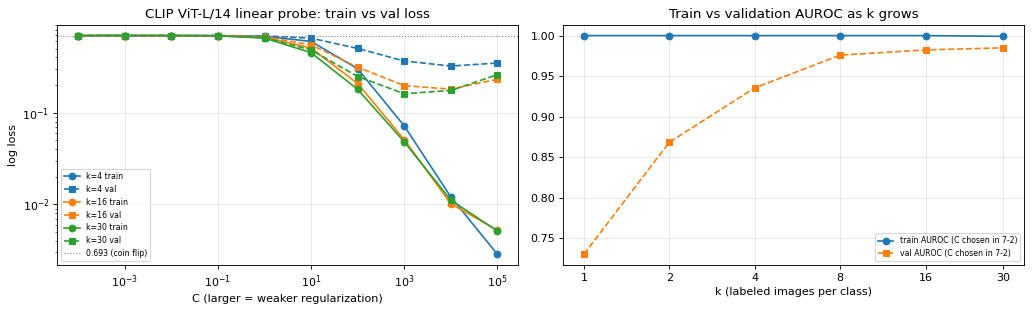

    train_AUROC  val_AUROC
k                         
1         1.000      0.730
2         1.000      0.868
4         1.000      0.935
8         1.000      0.976
16        1.000      0.982
30        0.999      0.985



In [9]:
# C(0.0001 ~ 100000), k별 train / val log loss
from sklearn.metrics import log_loss
C_WIDE = [1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100, 1e3, 1e4, 1e5]
Fx = FEATS['CLIP ViT-L/14']
rows = []
for seed in SEEDS:
    sp = make_split(seed)
    rng = np.random.RandomState(500 + seed)  # 7-2랑 같은 k장을 쓰려고 같은 seed
    pn, pa = rng.permutation(sp['train_n']), rng.permutation(sp['train_a'])
    va = np.r_[sp['val_n'], sp['val_a']]; yv = np.r_[np.zeros(len(sp['val_n'])), np.ones(len(sp['val_a']))]
    wv = np.where(yv == 1, 0.5 / yv.sum(), 0.5 / (1 - yv).sum())
    for k in [4, 16, 30]:
        tr = np.r_[pn[:k], pa[:k]]; ytr = np.r_[np.zeros(k), np.ones(k)]
        for C in C_WIDE:
            clf = LogisticRegression(C=C, max_iter=20000).fit(Fx[tr], ytr)
            rows.append(dict(seed=seed, k=k, C=C,
                             train_loss=log_loss(ytr, clf.predict_proba(Fx[tr])[:, 1], labels=[0, 1]),
                             val_loss=log_loss(yv, clf.predict_proba(Fx[va])[:, 1], sample_weight=wv, labels=[0, 1]),
                             train_acc=clf.score(Fx[tr], ytr), val_AUROC=fast_auc(yv, clf.decision_function(Fx[va]))))
dfC = pd.DataFrame(rows)
tblC = dfC.groupby(['k', 'C'])[['train_loss', 'val_loss', 'train_acc', 'val_AUROC']].mean()
print('[CLIP ViT-L/14, 분할 5개 평균]')
print(tblC.round(3).to_string())
bestC = tblC.reset_index().loc[lambda d: d.groupby('k').val_loss.idxmin()]
print('\nval loss가 가장 낮았던 C:')
print(bestC[['k', 'C', 'train_loss', 'val_loss', 'val_AUROC']].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for j, k in enumerate([4, 16, 30]):
    s = dfC[dfC.k == k].groupby('C')[['train_loss', 'val_loss']].mean()
    axes[0].plot(s.index, s.train_loss, marker='o', color=f'C{j}', label=f'k={k} train')
    axes[0].plot(s.index, s.val_loss, marker='s', ls='--', color=f'C{j}', label=f'k={k} val')
axes[0].axhline(np.log(2), color='gray', ls=':', lw=1, label='0.693 (coin flip)')
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].set_xlabel('C (larger = weaker regularization)'); axes[0].set_ylabel('log loss')
axes[0].set_title('CLIP ViT-L/14 linear probe: train vs val loss')
best_c = dfL[dfL.feat == 'CLIP ViT-L/14'][['seed', 'k', 'C']]
gap = dfH[dfH.feat == 'CLIP ViT-L/14'].merge(best_c, on=['seed', 'k', 'C']).groupby('k')[['train_AUROC', 'val_AUROC']].mean()
axes[1].plot(gap.index, gap.train_AUROC, marker='o', label='train AUROC (C chosen in 7-2)')
axes[1].plot(gap.index, gap.val_AUROC, marker='s', ls='--', label='val AUROC (C chosen in 7-2)')
axes[1].set_xscale('log', base=2); axes[1].set_xticks(KS); axes[1].set_xticklabels(KS); axes[1].set_xlabel('k (labeled images per class)')
axes[1].set_title('Train vs validation AUROC as k grows')
for a in axes:
    a.grid(alpha=0.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(gap.round(3).to_string())

| C 구간 | 결과 (CLIP ViT-L/14, 분할 5개 평균) | 판단 |
|---|---|---|
| 0.1 이하 | train, val loss 둘 다 0.69(찍기 수준) | 과소적합. 규제가 너무 세서 확률을 0.5 근처로만 냄 |
| 1,000 ~ 10,000 | train 0.01 ~ 0.05, val loss 최저(k=4: 0.323, k=16: 0.180, k=30: 0.161) | 적당 |
| 100,000 | train 0.003 ~ 0.005로 더 내려가는데 val은 다시 오름(k=4: 0.348, k=16: 0.232, k=30: 0.259) | 과적합 |

왼쪽 그래프에서 실선(train)은 C가 커질수록 계속 내려가는데, 점선(val)은 C가 작을 땐 0.69에 붙어 있다가 내려가서 10³ ~ 10⁴에서 바닥을 찍고 10⁵에서 다시 올라간다.

같은 C에서도 학습 이미지가 적을수록 train/val 차이가 컸다. C=1,000에서 k=4는 train 0.072 / val 0.366, k=30은 0.048 / 0.161이다.

오른쪽 그래프처럼 train AUROC는 k랑 상관없이 거의 1.0인데 val AUROC는 k=1에서 0.730, k=30에서 0.985다. 이미지가 적으면 학습 데이터만 완벽하게 맞히는 과적합 상태고, 데이터가 늘수록 차이가 줄었다(0.27 → 0.014).

과소적합은 AUROC로는 안 보이고 loss로 봐야 보였다. 7-2에서는 C를 AUROC로 골라서 순위 성능엔 문제가 없지만, 확률값 자체를 판정 기준으로 쓰려면 C를 1,000 근처로 키워야 한다.

In [10]:
# 요약 (아래 정리에 쓴 숫자)
print('zero-shot:', {k: f"{dfZ[dfZ.config == k].AUROC.mean():.3f} ± {dfZ[dfZ.config == k].AUROC.std():.3f}" for k in ZS})
print('linear probe k=30:', {f: f"{dfL[(dfL.feat == f) & (dfL.k == 30)].test_AUROC.mean():.3f} ± {dfL[(dfL.feat == f) & (dfL.k == 30)].test_AUROC.std():.3f}" for f in FEATS})
print('linear probe k=4:', {f: f"{dfL[(dfL.feat == f) & (dfL.k == 4)].test_AUROC.mean():.3f}" for f in FEATS})

zero-shot: {'ViT-B/32 / single prompt': '0.704 ± 0.032', 'ViT-B/32 / ensemble (40)': '0.708 ± 0.031', 'ViT-L/14 / single prompt': '0.737 ± 0.019', 'ViT-L/14 / ensemble (40)': '0.602 ± 0.014'}
linear probe k=30: {'CLIP ViT-B/32': '0.973 ± 0.011', 'CLIP ViT-L/14': '0.977 ± 0.012', 'ResNet-50 (ImageNet)': '0.958 ± 0.022'}
linear probe k=4: {'CLIP ViT-B/32': '0.945', 'CLIP ViT-L/14': '0.928', 'ResNet-50 (ImageNet)': '0.871'}



### 7-4. 정리

- 비교한 것: 같은 테스트셋에서 zero-shot(문장 1개 / 앙상블, B/32 / L/14)이랑 같은 특징에 라벨 k장으로 학습한 linear probe
- 믿을 만한 결론: (1) PCB 결함 판별에서 zero-shot CLIP은 AUROC 0.60 ~ 0.74로 약하다. (2) 라벨이 클래스당 4장만 있어도 0.93 이상으로 확 좋아진다. (3) ViT-L/14에서 앙상블은 오히려 나빴다. (1), (2)는 차이가 분할 표준편차보다 훨씬 크고, (3)은 5개 분할 다 신뢰구간이 0을 안 걸쳤다.
- 믿기 어려운 것: k=1 ~ 2의 평균값(표준편차가 너무 큼), ViT-B/32 앙상블 효과(신뢰구간이 0을 걸침), 분할 하나 기준의 작은 차이
- 논문이랑 비교하면: 앙상블 효과랑 "zero-shot = 4-shot"은 여기서 재현이 안 됐지만, 전문적인 작업에서 zero-shot이 약하다는 논문 설명(3.1.5절)이랑은 맞았다.

## 8. 회고 (KPT)

**Keep**
- 질문 5개를 먼저 정해 놓고 읽으니 48쪽짜리 논문에서 뭘 찾아야 할지 분명해서 덜 막막했습니다.
- 논문에 나온 걸 그대로 받아들이지 않고 같은 테스트셋, 분할 5개, 신뢰구간으로 직접 다시 확인해 본 것. 앙상블처럼 논문에서는 좋았던 방법이 이 데이터에서는 오히려 나빠질 수 있다는 걸 알았습니다.

**Problem**
- 대조 학습 손실(N×N 유사도에 대한 대칭 cross-entropy)이나 temperature는 Figure 3 의사코드 수준으로만 이해했고 수식으로 설명하긴 아직 어렵습니다.
- 6장 실험은 이미지가 4장이라 결론을 못 냈습니다. 7장에서 다시 했지만 테스트 불량이 50장이라 분할 하나의 신뢰구간이 ±0.08 정도로 여전히 넓었습니다.
- ViT-L/14에서 앙상블이 왜 나빠졌는지 원인을 못 찾았습니다. 논문 표의 제일 큰 모델(ViT-L/14@336px)이 아니라 224px 모델을 쓴 것도 차이가 있습니다.
- 처음에 AUROC만 보고 과소적합을 판단하려다가 안 보여서 log loss로 다시 봤습니다. 지표마다 보여주는 게 다르다는 걸 미리 생각하지 못했습니다.

**Try**
- 앙상블 문장을 하나씩 빼보면서 어떤 문장이 ViT-L/14 성능을 떨어뜨리는지 찾아보기
- 이미지 전체 대신 작은 패치마다 CLIP 점수를 매기는 WinCLIP 방식으로 zero-shot이 얼마나 오르는지 보기
- Figure 3 의사코드를 PyTorch로 옮겨서 작은 배치에서 N×N 유사도랑 loss가 어떻게 계산되는지 직접 찍어보기

CLIP을 읽고 나니 VLM 실습이나 AnomalyAny처럼 이미지랑 문장을 같이 쓰는 방법들이 다 여기서 출발한다는 게 보였습니다. 그런데 이번 실험에서 zero-shot AUROC는 0.60 ~ 0.74였고, 같은 CLIP 특징에 정상/불량 4장씩만 붙여 학습해도 0.93 넘게 나왔습니다. 말로 설명만 하면 다 되는 게 아니라, 제조 결함처럼 미세한 차이는 적은 라벨이라도 따로 학습시켜야 한다는 걸 알게 됐습니다.